In [4]:
import mygene
import pyreadr
import numpy as np
from scipy.sparse.csgraph import connected_components
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import dynamo as dyn

In [5]:
adata = sc.read('/home/csb/Saloni/SCENT/data/endocrinogenesis_day15.h5ad')

print(adata)

AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'


/home/csb/Saloni/EMT_ID/EMT_ID/.venv/lib/python3.10/site-packages/anndata/compat/__init__.py:371: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  warn(
/home/csb/Saloni/EMT_ID/EMT_ID/.venv/lib/python3.10/site-packages/anndata/compat/__init__.py:371: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  warn(


In [3]:
result = pyreadr.read_r("/home/csb/Saloni/SCENT/data/net17Jan16.rda")
print(result.keys())                    # confirm the actual object name it loaded
net_df = result['net17Jan16.m']          # adjust key if pyreadr reports something else

net_gene_ids = net_df.index.astype(str).tolist()   # Entrez IDs, as strings
A_full = net_df.values.astype(np.float32)

print(A_full.shape)
assert np.allclose(A_full, A_full.T)
assert np.all(np.diag(A_full) == 0)

odict_keys(['net17Jan16.m'])
(11751, 11751)


In [4]:
import mygene

mg = mygene.MyGeneInfo()

# Query as MOUSE genes, ask for the human ortholog via homologene
query = mg.querymany(
    adata.var_names.tolist(),
    scopes='symbol,alias',
    fields='entrezgene,homologene',
    species='mouse',
    returnall=True
)

symbol_to_entrez = {}

for q in query['out']:
    if 'homologene' in q and 'genes' in q['homologene']:
        for taxid, entrez in q['homologene']['genes']:
            if taxid == 9606:  # human
                symbol_to_entrez[q['query']] = str(entrez)
                break

print(f"Mapped: {len(symbol_to_entrez)} / {adata.n_vars}")

2731 input query terms found dup hits:	[('Rp1', 4), ('4732440D04Rik', 2), ('Gm26901', 2), ('Tram1', 2), ('Gm28153', 2), ('Defb41', 2), ('Gm
963 input query terms found no hit:	['Rp1-1', 'Gm43543', 'Gm26683', 'Gm28928', 'Gm26979', 'BC003331', 'Gm28513', 'Gm29291', 'Gm26523', '


Mapped: 17033 / 27998


In [5]:
common_symbols = [s for s in symbol_to_entrez if symbol_to_entrez[s] in net_gene_ids]
common_entrez = [symbol_to_entrez[s] for s in common_symbols]

entrez_idx = [net_gene_ids.index(e) for e in common_entrez]
A_sub = A_full[np.ix_(entrez_idx, entrez_idx)]

n_comp, labels = connected_components(A_sub, directed=False)
largest = np.bincount(labels).argmax()
mask = labels == largest

A_final = A_sub[mask][:, mask]
final_symbols = [s for s, m in zip(common_symbols, mask) if m]

print(f"Final network-aligned gene set: {len(final_symbols)} genes")
# Sanity check target: SCENT/CCAT papers typically retain 8,000-12,000 genes.
# If you're far below that, something's off upstream — worth a look before continuing.

Final network-aligned gene set: 10986 genes


In [6]:
adata_sub = adata[:, final_symbols].copy()
X_raw = adata_sub.X.toarray() if hasattr(adata_sub.X, 'toarray') else adata_sub.X

X_log = np.log(X_raw + 1.1).astype(np.float32)

In [7]:
def compute_CCAT_vectorized(X, A):
    """X: (n_cells, n_genes) log-normalized expression.
       A: (n_genes, n_genes) adjacency matrix, same gene order as X's columns."""
    k = A.sum(axis=1)                        # node degree, (n_genes,)
    k_c = k - k.mean()
    X_c = X - X.mean(axis=1, keepdims=True)

    cov = X_c @ k_c
    std_x = np.sqrt((X_c ** 2).sum(axis=1))
    std_k = np.sqrt((k_c ** 2).sum())

    return cov / (std_x * std_k)

adata.obs['CCAT'] = compute_CCAT_vectorized(X_log, A_final)
print(adata.obs['CCAT'].describe())

count    3696.000000
mean        0.351724
std         0.033148
min         0.248194
25%         0.329573
50%         0.346933
75%         0.368723
max         0.472415
Name: CCAT, dtype: float64


In [8]:
adata.obs.groupby("clusters")["CCAT"].describe()

/tmp/ipykernel_780829/3874991944.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("clusters")["CCAT"].describe()


,count,mean,std,min,25%,50%,75%,max
clusters,,,,,,,,
Ductal,916.0,0.387004,0.030981,0.297158,0.364032,0.384800,0.410625,0.472415
Ngn3 low EP,262.0,0.374067,0.025270,0.309309,0.356519,0.372262,0.392822,0.448508
Ngn3 high EP,642.0,0.355589,0.016917,0.302227,0.344988,0.355477,0.364952,0.425126
Pre-endocrine,592.0,0.335477,0.015130,0.274664,0.324992,0.335824,0.345972,0.389510
Beta,591.0,0.331433,0.018881,0.260703,0.319298,0.333476,0.343714,0.386237
Alpha,481.0,0.324995,0.018691,0.265005,0.313143,0.325813,0.336916,0.391853
Delta,70.0,0.311972,0.022073,0.257742,0.297402,0.313561,0.329014,0.351489
Epsilon,142.0,0.327753,0.022090,0.248194,0.313075,0.326904,0.342833,0.376145


First 4 vs terminal: t = 43.583, p = 0.000e+00
First 3 vs terminal: t = 52.231, p = 0.000e+00
First 2 vs terminal: t = 54.250, p = 0.000e+00
First 4 vs terminal: p = 0.000e+00, FDR-adjusted p = 0.000e+00
First 3 vs terminal: p = 0.000e+00, FDR-adjusted p = 0.000e+00
First 2 vs terminal: p = 0.000e+00, FDR-adjusted p = 0.000e+00


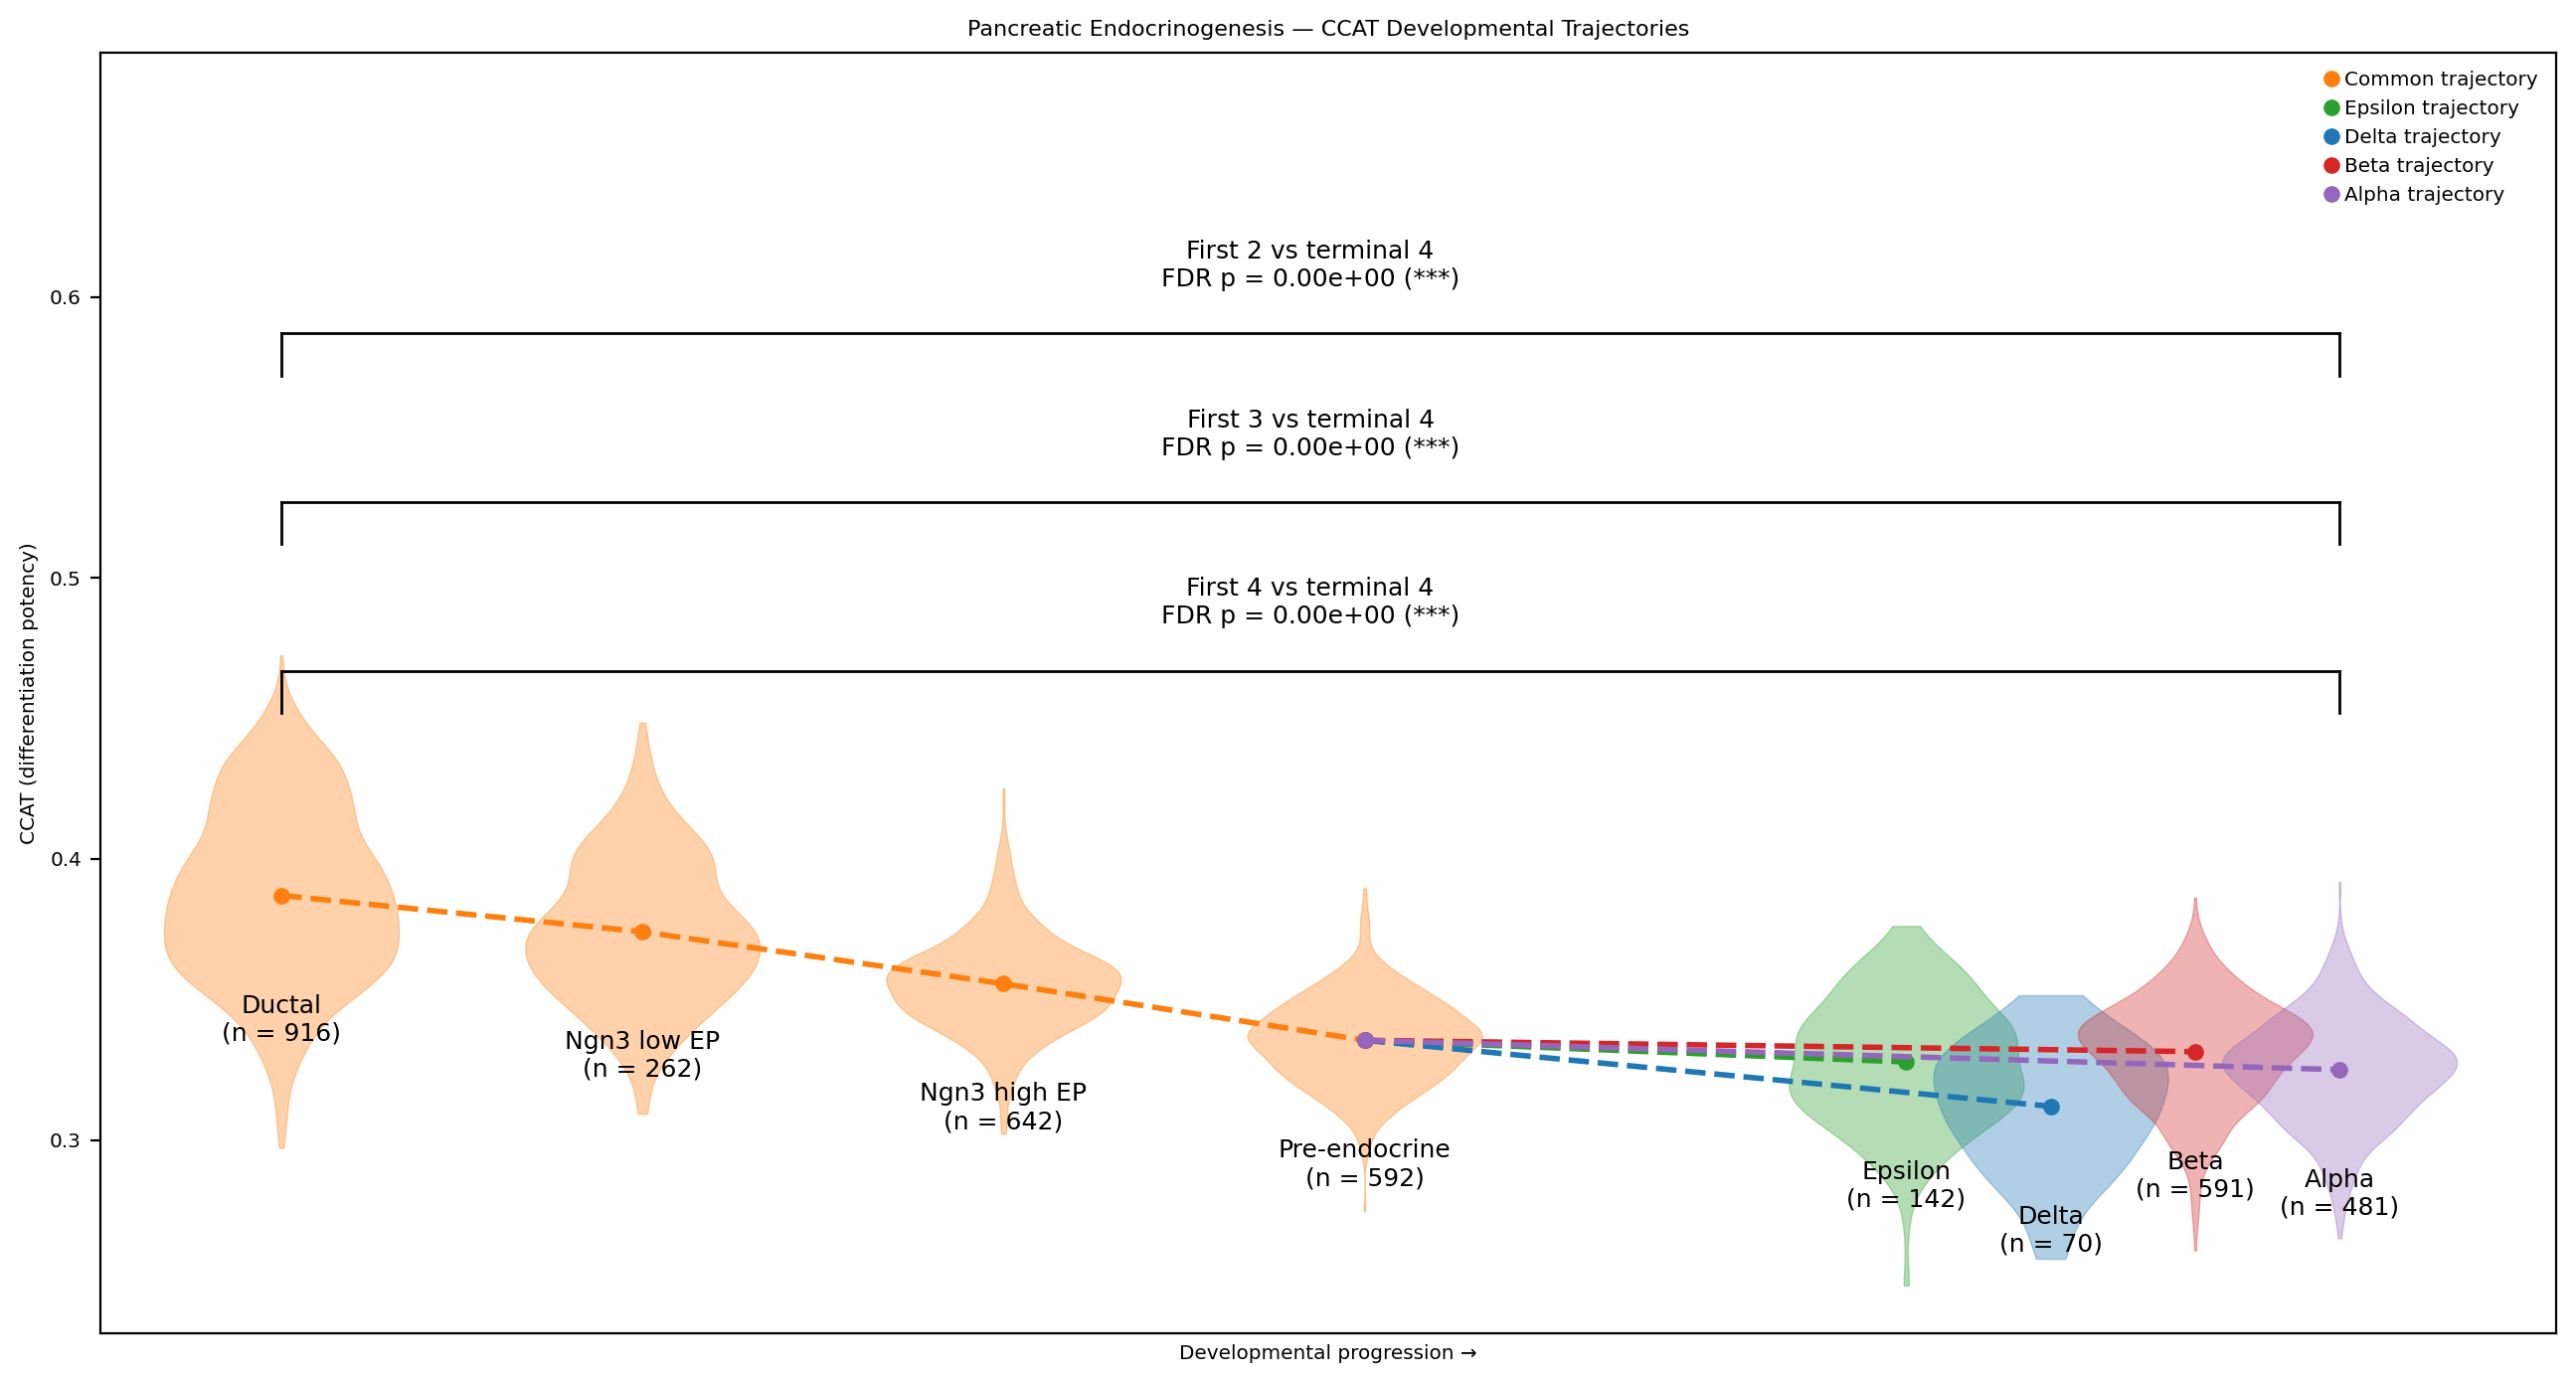

In [9]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER — NEW PANC ENDO DATASET
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine",
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]


# ============================================================
# GET CCAT DISTRIBUTIONS
# ============================================================

ccat_groups = {
    name: adata.obs.loc[
        adata.obs["clusters"] == name,
        "CCAT"
    ].dropna().values
    for name in cluster
}


# ============================================================
# MEAN CCAT
# ============================================================

ccat_means = {
    name: np.mean(values)
    for name, values in ccat_groups.items()
    if len(values) > 0
}


# ============================================================
# NUMBER OF CELLS
# ============================================================

cell_counts = {
    name: len(values)
    for name, values in ccat_groups.items()
}


# ============================================================
# X POSITIONS
#
# Common trajectory:
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
#
#                                      ├── Epsilon
#                                      ├── Delta
#                                      ├── Beta
#                                      └── Alpha
# ============================================================

x = {

    # Common trajectory
    "Ductal":        0.0,
    "Ngn3 low EP":   1.0,
    "Ngn3 high EP":  2.0,
    "Pre-endocrine": 3.0,

    # Terminal branches
    "Epsilon":       4.5,
    "Delta":         4.9,
    "Beta":          5.3,
    "Alpha":         5.7,
}


# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":    "tab:orange",
    "epsilon": "tab:green",
    "delta":   "tab:blue",
    "beta":    "tab:red",
    "alpha":   "tab:purple"
}


# ============================================================
# ASSIGN EACH CLUSTER TO A TRAJECTORY
# ============================================================

trajectory = {

    # Common trajectory
    "Ductal":        "main",
    "Ngn3 low EP":   "main",
    "Ngn3 high EP":  "main",
    "Pre-endocrine": "main",

    # Branches
    "Epsilon":       "epsilon",
    "Delta":         "delta",
    "Beta":          "beta",
    "Alpha":         "alpha",
}


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# DRAW VIOLINS
# ============================================================

for name in cluster:

    if name not in ccat_groups:
        continue

    values = ccat_groups[name]

    if len(values) == 0:
        continue

    color = colors[trajectory[name]]

    vp = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Same trajectory = same violin color
    for body in vp["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.35)


# ============================================================
# MAIN / COMMON TRAJECTORY
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
# ============================================================

main_path = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]

ax.plot(
    [x[name] for name in main_path],
    [ccat_means[name] for name in main_path],
    "o--",
    color=colors["main"],
    linewidth=2,
    markersize=5,
    label="Common trajectory",
    zorder=4
)


# ============================================================
# EPSILON BRANCH
#
# Pre-endocrine → Epsilon
# ============================================================

epsilon_path = [
    "Pre-endocrine",
    "Epsilon"
]

ax.plot(
    [x[name] for name in epsilon_path],
    [ccat_means[name] for name in epsilon_path],
    "o--",
    color=colors["epsilon"],
    linewidth=2,
    markersize=5,
    label="Epsilon trajectory",
    zorder=4
)


# ============================================================
# DELTA BRANCH
#
# Pre-endocrine → Delta
# ============================================================

delta_path = [
    "Pre-endocrine",
    "Delta"
]

ax.plot(
    [x[name] for name in delta_path],
    [ccat_means[name] for name in delta_path],
    "o--",
    color=colors["delta"],
    linewidth=2,
    markersize=5,
    label="Delta trajectory",
    zorder=4
)


# ============================================================
# BETA BRANCH
#
# Pre-endocrine → Beta
# ============================================================

beta_path = [
    "Pre-endocrine",
    "Beta"
]

ax.plot(
    [x[name] for name in beta_path],
    [ccat_means[name] for name in beta_path],
    "o--",
    color=colors["beta"],
    linewidth=2,
    markersize=5,
    label="Beta trajectory",
    zorder=4
)


# ============================================================
# ALPHA BRANCH
#
# Pre-endocrine → Alpha
# ============================================================

alpha_path = [
    "Pre-endocrine",
    "Alpha"
]

ax.plot(
    [x[name] for name in alpha_path],
    [ccat_means[name] for name in alpha_path],
    "o--",
    color=colors["alpha"],
    linewidth=2,
    markersize=5,
    label="Alpha trajectory",
    zorder=4
)


# ============================================================
# LABELS
# ============================================================

for name in cluster:

    if name not in ccat_means:
        continue

    ax.text(
        x[name],
        ccat_means[name] - 0.035,
        f"{name}\n(n = {cell_counts[name]})",
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 6.3)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("CCAT (differentiation potency)")

ax.set_title(
    "Pancreatic Endocrinogenesis — CCAT Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="best"
)

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# DEFINE GROUPS
# ============================================================

terminal_clusters = [
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]

group1_4 = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]

group1_3 = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP"
]

group1_2 = [
    "Ductal",
    "Ngn3 low EP"
]


# ============================================================
# COMBINE CELL-LEVEL CCAT VALUES
# ============================================================

def combine_ccat(clusters):

    return np.concatenate([
        ccat_groups[name]
        for name in clusters
        if name in ccat_groups and len(ccat_groups[name]) > 0
    ])


terminal_values = combine_ccat(terminal_clusters)

early4_values = combine_ccat(group1_4)
early3_values = combine_ccat(group1_3)
early2_values = combine_ccat(group1_2)


# ============================================================
# WELCH T-TESTS
# ============================================================

comparisons = [
    ("First 4", early4_values, terminal_values),
    ("First 3", early3_values, terminal_values),
    ("First 2", early2_values, terminal_values)
]

p_values = []

for label, group1, group2 in comparisons:

    statistic, p = ttest_ind(
        group1,
        group2,
        equal_var=False
    )

    p_values.append(p)

    print(
        f"{label} vs terminal: "
        f"t = {statistic:.3f}, "
        f"p = {p:.3e}"
    )


# ============================================================
# FDR CORRECTION
# ============================================================

p_adj = multipletests(
    p_values,
    method="fdr_bh"
)[1]


# ============================================================
# PRINT RESULTS
# ============================================================

for (label, _, _), p, padj in zip(
    comparisons,
    p_values,
    p_adj
):

    print(
        f"{label} vs terminal: "
        f"p = {p:.3e}, "
        f"FDR-adjusted p = {padj:.3e}"
    )


# ============================================================
# HELPER FOR SIGNIFICANCE LABEL
# ============================================================

def significance_label(p):

    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


# ============================================================
# DRAW HORIZONTAL COMPARISON LINES
# ============================================================

# x-range covers the two groups being compared
x_left = x["Ductal"]
x_right = x["Alpha"]

# Heights above the plot
y_max = max(ccat_means.values())

bracket_heights = [
    y_max + 0.08,
    y_max + 0.14,
    y_max + 0.20
]

labels = [
    f"First 4 vs terminal 4\nFDR p = {p_adj[0]:.2e} ({significance_label(p_adj[0])})",
    f"First 3 vs terminal 4\nFDR p = {p_adj[1]:.2e} ({significance_label(p_adj[1])})",
    f"First 2 vs terminal 4\nFDR p = {p_adj[2]:.2e} ({significance_label(p_adj[2])})"
]


# ============================================================
# DRAW BRACKETS
# ============================================================

for height, label in zip(bracket_heights, labels):

    # horizontal line
    ax.plot(
        [x_left, x_right],
        [height, height],
        color="black",
        linewidth=1
    )

    # vertical ticks
    tick_height = 0.015

    ax.plot(
        [x_left, x_left],
        [height, height - tick_height],
        color="black",
        linewidth=1
    )

    ax.plot(
        [x_right, x_right],
        [height, height - tick_height],
        color="black",
        linewidth=1
    )

    # label
    ax.text(
        (x_left + x_right) / 2,
        height + 0.015,
        label,
        ha="center",
        va="bottom",
        fontsize=9
    )


# ============================================================
# EXPAND Y LIMIT TO FIT STATISTICS
# ============================================================

ax.set_ylim(
    ax.get_ylim()[0],
    y_max + 0.30
)

plt.tight_layout()
plt.show()


CCAT GROUP-WISE STATISTICS


,Comparison,n_group1,n_terminal,t_stat,p_value,p_adj
0,First 4 vs terminal 4,2412,1284,43.583416,0.0,0.0
1,First 3 vs terminal 4,1820,1284,52.231095,0.0,0.0
2,First 2 vs terminal 4,1178,1284,54.250115,0.0,0.0


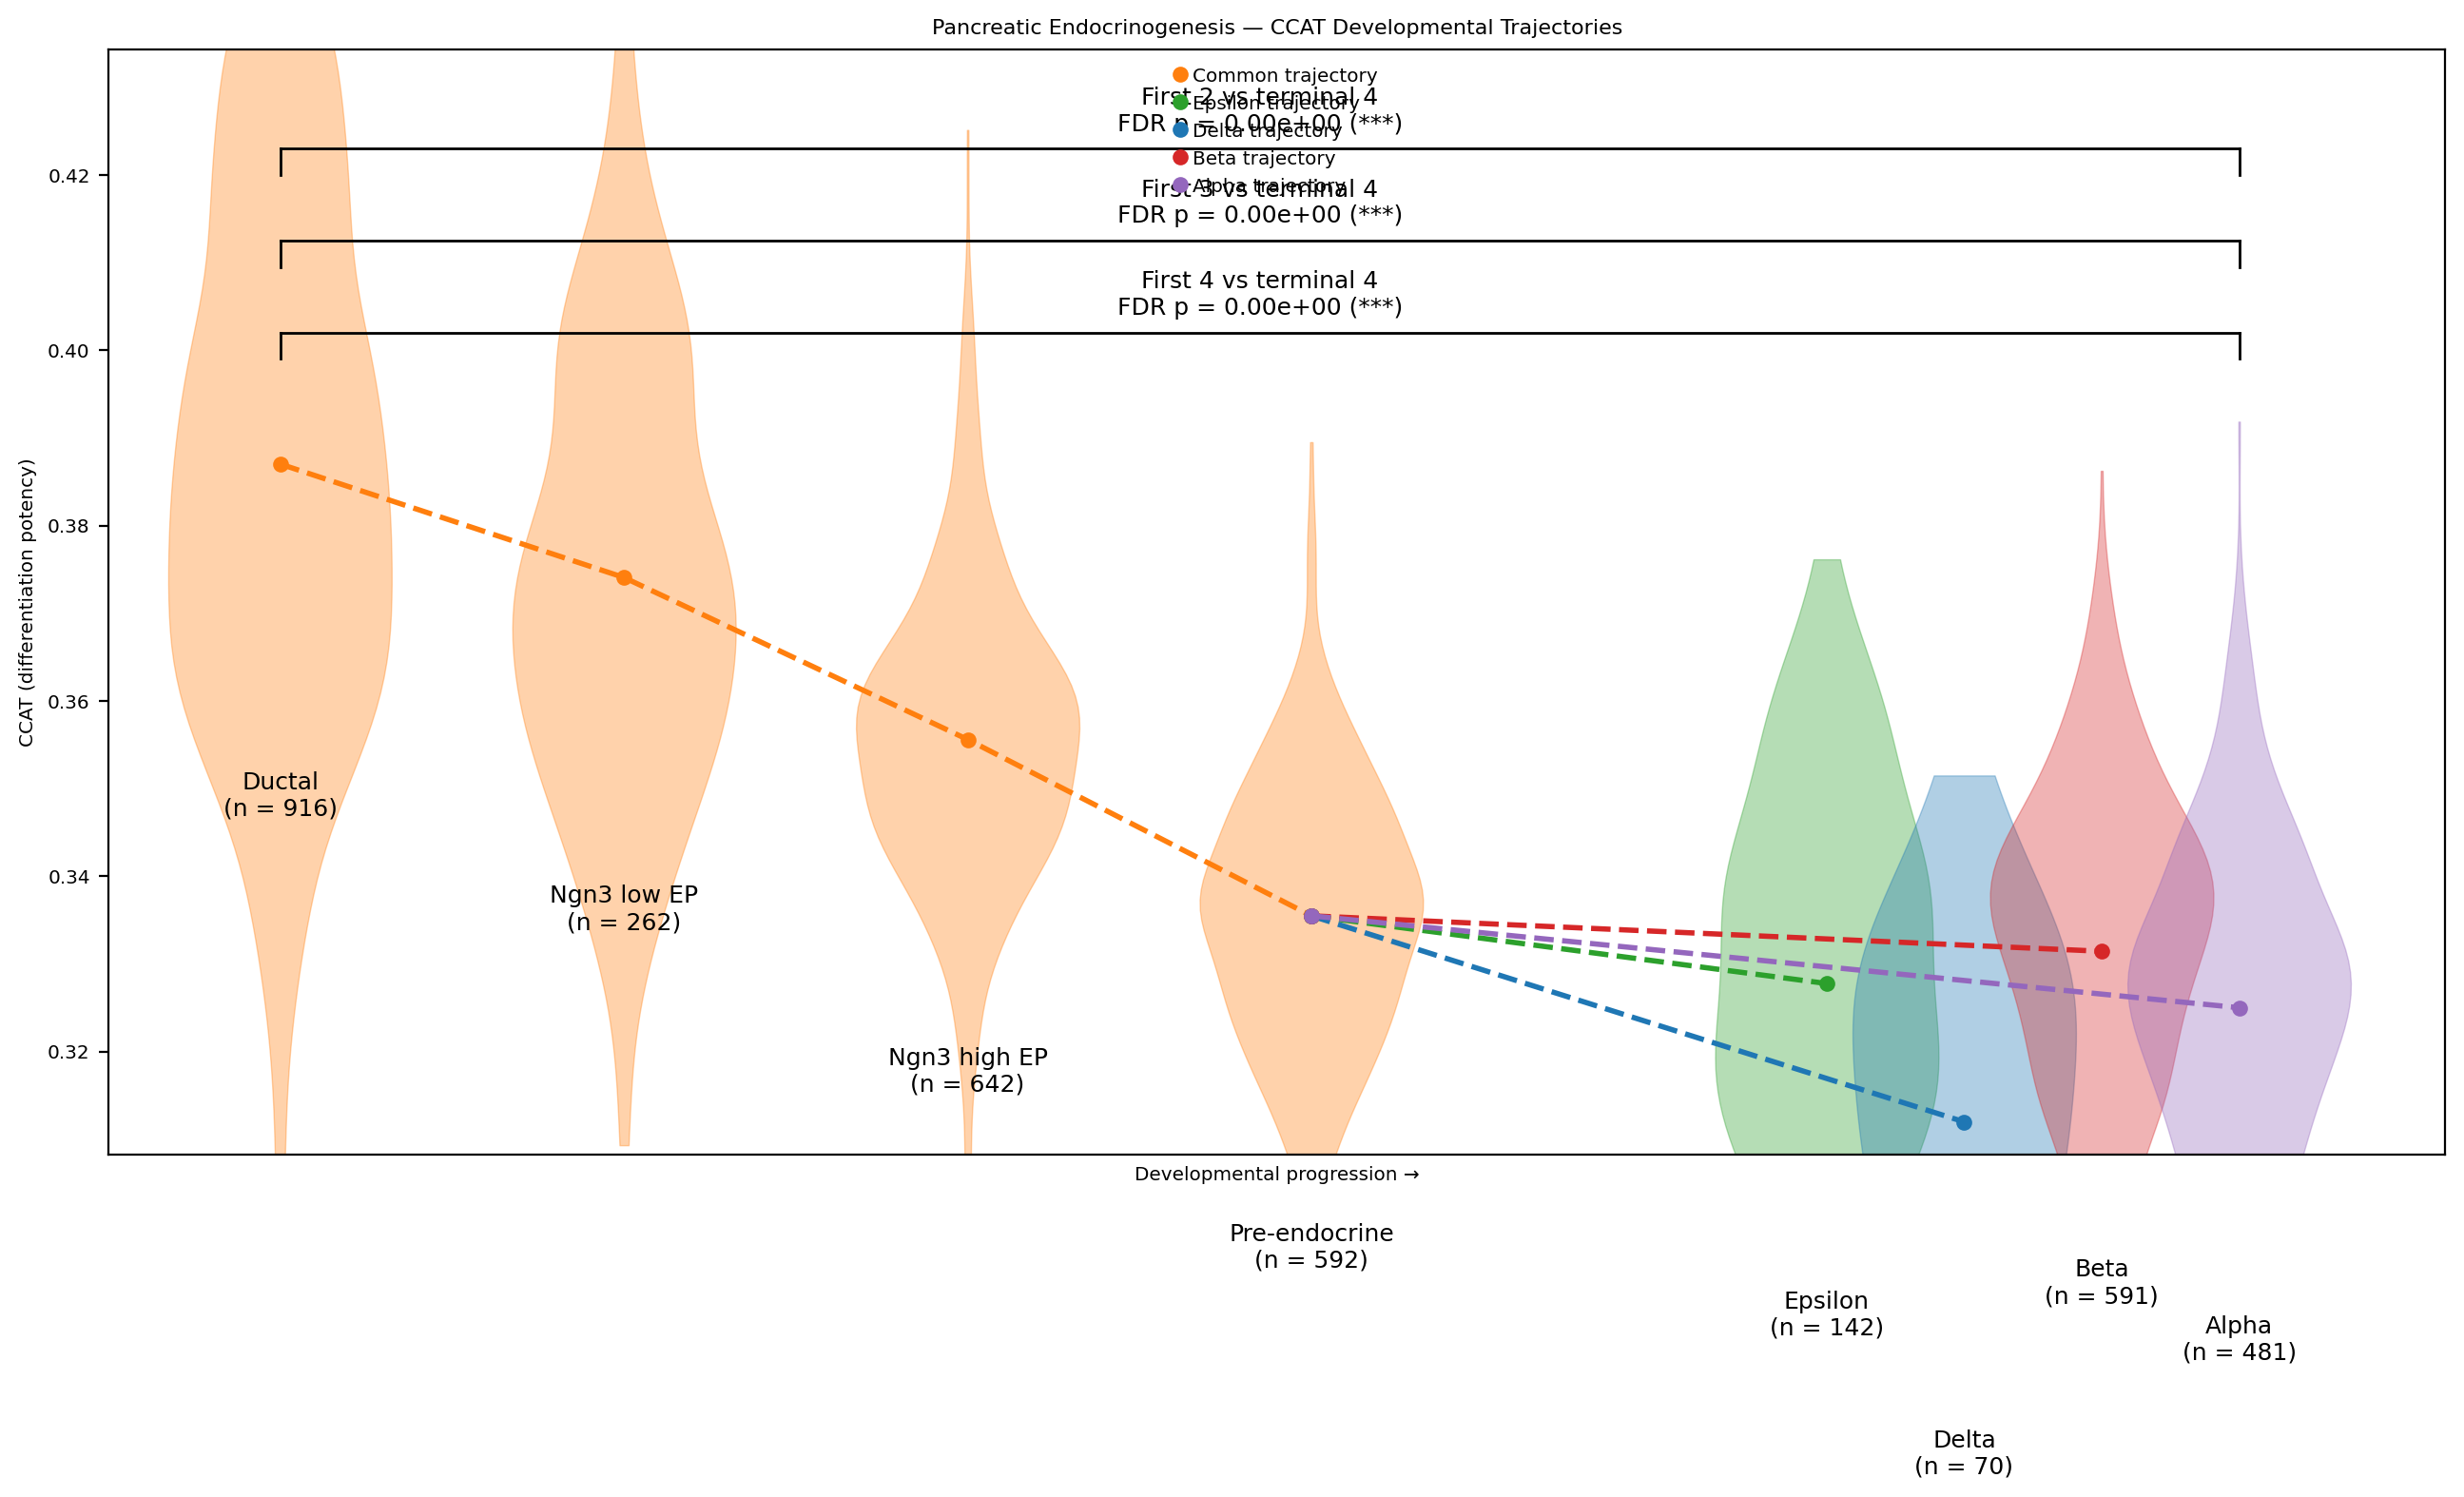

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# DEVELOPMENTAL ORDER — PANCREATIC ENDOCRINOGENESIS
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine",
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]


# ============================================================
# GET CCAT DISTRIBUTIONS
# ============================================================

ccat_groups = {
    name: adata.obs.loc[
        adata.obs["clusters"] == name,
        "CCAT"
    ].dropna().values
    for name in cluster
}


# ============================================================
# MEAN CCAT
# ============================================================

ccat_means = {
    name: np.mean(values)
    for name, values in ccat_groups.items()
    if len(values) > 0
}


# ============================================================
# NUMBER OF CELLS
# ============================================================

cell_counts = {
    name: len(values)
    for name, values in ccat_groups.items()
}


# ============================================================
# X POSITIONS
# ============================================================

x = {

    # Common trajectory
    "Ductal":        0.0,
    "Ngn3 low EP":   1.0,
    "Ngn3 high EP":  2.0,
    "Pre-endocrine": 3.0,

    # Terminal branches
    "Epsilon":       4.5,
    "Delta":         4.9,
    "Beta":          5.3,
    "Alpha":         5.7,
}


# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":    "tab:orange",
    "epsilon": "tab:green",
    "delta":   "tab:blue",
    "beta":    "tab:red",
    "alpha":   "tab:purple"
}


# ============================================================
# ASSIGN EACH CLUSTER TO A TRAJECTORY
# ============================================================

trajectory = {

    # Common trajectory
    "Ductal":        "main",
    "Ngn3 low EP":   "main",
    "Ngn3 high EP":  "main",
    "Pre-endocrine": "main",

    # Terminal branches
    "Epsilon": "epsilon",
    "Delta":   "delta",
    "Beta":    "beta",
    "Alpha":   "alpha",
}


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(13, 8))


# ============================================================
# DRAW VIOLINS
# ============================================================

for name in cluster:

    if name not in ccat_groups:
        continue

    values = ccat_groups[name]

    if len(values) == 0:
        continue

    color = colors[trajectory[name]]

    vp = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Same trajectory = same violin color
    for body in vp["bodies"]:

        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.35)


# ============================================================
# MAIN / COMMON TRAJECTORY
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
# ============================================================

main_path = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]

ax.plot(
    [x[name] for name in main_path],
    [ccat_means[name] for name in main_path],
    "o--",
    color=colors["main"],
    linewidth=2,
    markersize=5,
    label="Common trajectory",
    zorder=4
)


# ============================================================
# EPSILON BRANCH
# ============================================================

epsilon_path = [
    "Pre-endocrine",
    "Epsilon"
]

ax.plot(
    [x[name] for name in epsilon_path],
    [ccat_means[name] for name in epsilon_path],
    "o--",
    color=colors["epsilon"],
    linewidth=2,
    markersize=5,
    label="Epsilon trajectory",
    zorder=4
)


# ============================================================
# DELTA BRANCH
# ============================================================

delta_path = [
    "Pre-endocrine",
    "Delta"
]

ax.plot(
    [x[name] for name in delta_path],
    [ccat_means[name] for name in delta_path],
    "o--",
    color=colors["delta"],
    linewidth=2,
    markersize=5,
    label="Delta trajectory",
    zorder=4
)


# ============================================================
# BETA BRANCH
# ============================================================

beta_path = [
    "Pre-endocrine",
    "Beta"
]

ax.plot(
    [x[name] for name in beta_path],
    [ccat_means[name] for name in beta_path],
    "o--",
    color=colors["beta"],
    linewidth=2,
    markersize=5,
    label="Beta trajectory",
    zorder=4
)


# ============================================================
# ALPHA BRANCH
# ============================================================

alpha_path = [
    "Pre-endocrine",
    "Alpha"
]

ax.plot(
    [x[name] for name in alpha_path],
    [ccat_means[name] for name in alpha_path],
    "o--",
    color=colors["alpha"],
    linewidth=2,
    markersize=5,
    label="Alpha trajectory",
    zorder=4
)


# ============================================================
# CLUSTER LABELS
# ============================================================

for name in cluster:

    if name not in ccat_means:
        continue

    ax.text(
        x[name],
        ccat_means[name] - 0.035,
        f"{name}\n(n = {cell_counts[name]})",
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING BEFORE STATISTICAL BRACKETS
# ============================================================

ax.set_xlim(-0.5, 6.3)

ax.set_xticks([])

ax.set_xlabel(
    "Developmental progression →"
)

ax.set_ylabel(
    "CCAT (differentiation potency)"
)

ax.set_title(
    "Pancreatic Endocrinogenesis — CCAT Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="best"
)


# ============================================================
# DEFINE BIOLOGICAL GROUPS
#
# Terminal group:
# Alpha + Beta + Delta + Epsilon
#
# Comparisons:
# 1. First 4 developmental states vs terminal group
# 2. First 3 developmental states vs terminal group
# 3. First 2 developmental states vs terminal group
# ============================================================

terminal_clusters = [
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]

early4_clusters = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]

early3_clusters = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP"
]

early2_clusters = [
    "Ductal",
    "Ngn3 low EP"
]


# ============================================================
# COMBINE CELL-LEVEL CCAT VALUES
# ============================================================

def combine_ccat(clusters):

    return np.concatenate([
        ccat_groups[name]
        for name in clusters
        if name in ccat_groups
        and len(ccat_groups[name]) > 0
    ])


terminal_values = combine_ccat(
    terminal_clusters
)

early4_values = combine_ccat(
    early4_clusters
)

early3_values = combine_ccat(
    early3_clusters
)

early2_values = combine_ccat(
    early2_clusters
)


# ============================================================
# WELCH T-TESTS
# ============================================================

comparisons = [
    (
        "First 4 vs terminal 4",
        early4_values,
        terminal_values
    ),
    (
        "First 3 vs terminal 4",
        early3_values,
        terminal_values
    ),
    (
        "First 2 vs terminal 4",
        early2_values,
        terminal_values
    )
]


results = []

for label, group1, group2 in comparisons:

    statistic, p = ttest_ind(
        group1,
        group2,
        equal_var=False
    )

    results.append({
        "Comparison": label,
        "n_group1": len(group1),
        "n_terminal": len(group2),
        "t_stat": statistic,
        "p_value": p
    })


# ============================================================
# FDR CORRECTION
# ============================================================

p_values = [
    result["p_value"]
    for result in results
]

p_adj = multipletests(
    p_values,
    method="fdr_bh"
)[1]


for result, padj in zip(
    results,
    p_adj
):

    result["p_adj"] = padj


# ============================================================
# RESULTS TABLE
# ============================================================

stats_df = pd.DataFrame(results)

print("\n==============================================")
print("CCAT GROUP-WISE STATISTICS")
print("==============================================")

display(stats_df)


# ============================================================
# SIGNIFICANCE LABEL
# ============================================================

def significance_label(p):

    if p < 0.001:
        return "***"

    elif p < 0.01:
        return "**"

    elif p < 0.05:
        return "*"

    else:
        return "ns"


# ============================================================
# DETERMINE Y-RANGE
# ============================================================

y_max = max(
    ccat_means.values()
)

y_min = min(
    ccat_means.values()
)

y_range = y_max - y_min


# ============================================================
# BRACKET HEIGHTS
# ============================================================

bracket_heights = [
    y_max + 0.20 * y_range,
    y_max + 0.34 * y_range,
    y_max + 0.48 * y_range
]


# ============================================================
# BRACKET LABELS
# ============================================================

bracket_labels = [

    (
        f"First 4 vs terminal 4\n"
        f"FDR p = {p_adj[0]:.2e} "
        f"({significance_label(p_adj[0])})"
    ),

    (
        f"First 3 vs terminal 4\n"
        f"FDR p = {p_adj[1]:.2e} "
        f"({significance_label(p_adj[1])})"
    ),

    (
        f"First 2 vs terminal 4\n"
        f"FDR p = {p_adj[2]:.2e} "
        f"({significance_label(p_adj[2])})"
    )
]


# ============================================================
# DRAW STATISTICAL BRACKETS
# ============================================================

x_left = x["Ductal"]
x_right = x["Alpha"]


for height, label in zip(
    bracket_heights,
    bracket_labels
):

    # --------------------------------------------------------
    # Horizontal line
    # --------------------------------------------------------

    ax.plot(
        [x_left, x_right],
        [height, height],
        color="black",
        linewidth=1
    )

    # --------------------------------------------------------
    # Left vertical tick
    # --------------------------------------------------------

    ax.plot(
        [x_left, x_left],
        [
            height,
            height - 0.04 * y_range
        ],
        color="black",
        linewidth=1
    )

    # --------------------------------------------------------
    # Right vertical tick
    # --------------------------------------------------------

    ax.plot(
        [x_right, x_right],
        [
            height,
            height - 0.04 * y_range
        ],
        color="black",
        linewidth=1
    )

    # --------------------------------------------------------
    # P-value label
    # --------------------------------------------------------

    ax.text(
        (x_left + x_right) / 2,
        height + 0.02 * y_range,
        label,
        ha="center",
        va="bottom",
        fontsize=9
    )


# ============================================================
# EXPAND Y LIMIT TO FIT STATISTICS
# ============================================================

ax.set_ylim(
    y_min - 0.05 * y_range,
    bracket_heights[-1] + 0.15 * y_range
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.tight_layout()
plt.show()



Terminal group size: 1284

CCAT — EARLY VS TERMINAL GROUP


,Early_group,Terminal_group,n_early,n_terminal,t_stat,p_value,p_adj
0,Ductal,Alpha + Beta + Delta + Epsilon,916,1284,51.032833,0.000000e+00,0.000000e+00
1,Ngn3 low EP,Alpha + Beta + Delta + Epsilon,262,1284,28.066321,1.810815e-89,2.414420e-89
2,Ngn3 high EP,Alpha + Beta + Delta + Epsilon,642,1284,32.264879,1.869862e-173,3.739723e-173
3,Pre-endocrine,Alpha + Beta + Delta + Epsilon,592,1284,9.498614,8.222501e-21,8.222501e-21


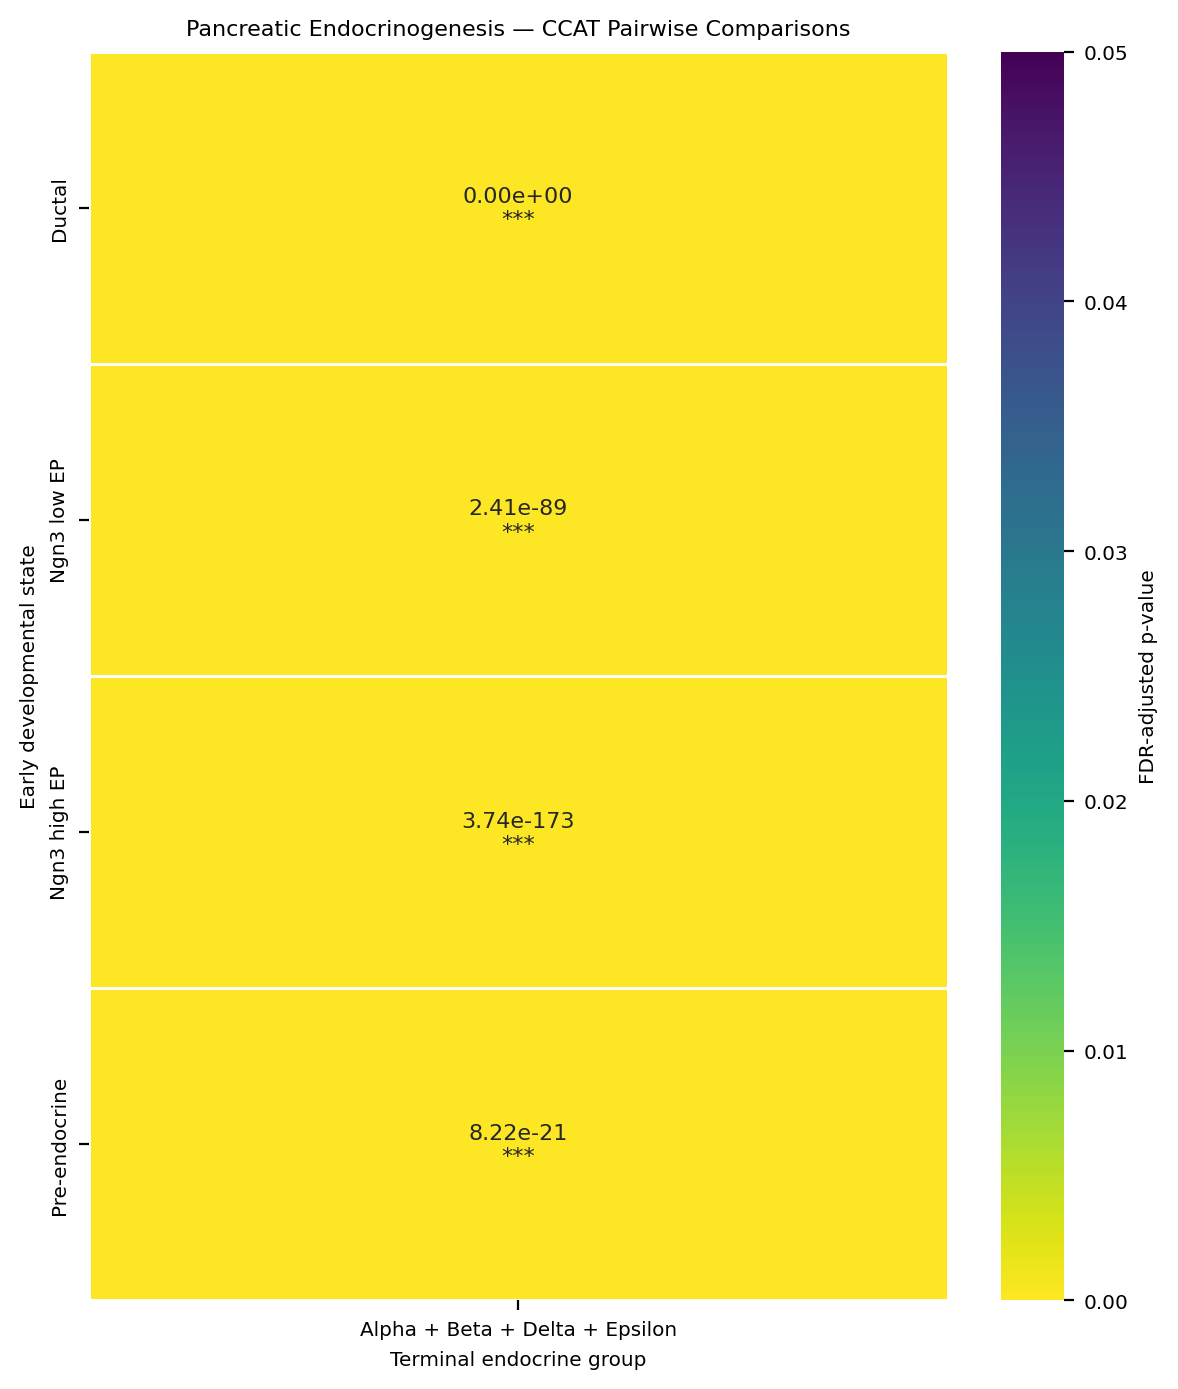

In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# DEFINE GROUPS
# ============================================================

early_clusters = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]

terminal_clusters = [
    "Alpha",
    "Beta",
    "Delta",
    "Epsilon"
]


# ============================================================
# GET CELL-LEVEL CCAT VALUES
# ============================================================

ccat_groups = {
    name: adata.obs.loc[
        adata.obs["clusters"] == name,
        "CCAT"
    ].dropna().values
    for name in (
        early_clusters + terminal_clusters
    )
}


# ============================================================
# COMBINE THE FOUR TERMINAL CELL TYPES
# ============================================================

terminal_values = np.concatenate([
    ccat_groups[name]
    for name in terminal_clusters
    if len(ccat_groups[name]) > 0
])


print(
    "Terminal group size:",
    len(terminal_values)
)


# ============================================================
# WELCH T-TEST
#
# Each early developmental state is compared against
# the pooled terminal endocrine group.
# ============================================================

results = []

for early in early_clusters:

    early_values = ccat_groups[early]

    statistic, p_value = ttest_ind(
        early_values,
        terminal_values,
        equal_var=False
    )

    results.append({
        "Early_group": early,
        "Terminal_group": "Alpha + Beta + Delta + Epsilon",
        "n_early": len(early_values),
        "n_terminal": len(terminal_values),
        "t_stat": statistic,
        "p_value": p_value
    })


# ============================================================
# FDR / BENJAMINI-HOCHBERG CORRECTION
# ============================================================

p_values = [
    result["p_value"]
    for result in results
]

p_adj = multipletests(
    p_values,
    method="fdr_bh"
)[1]


for result, padj in zip(results, p_adj):
    result["p_adj"] = padj


# ============================================================
# RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results)

print("\n==============================================")
print("CCAT — EARLY VS TERMINAL GROUP")
print("==============================================")

display(results_df)


# ============================================================
# CREATE HEATMAP MATRIX
# ============================================================

heatmap_data = pd.DataFrame(
    results_df["p_adj"].values,
    index=results_df["Early_group"],
    columns=["Alpha + Beta + Delta + Epsilon"]
)


# ============================================================
# ANNOTATION
# ============================================================

annot = heatmap_data.copy().astype(str)

for i in range(heatmap_data.shape[0]):

    value = heatmap_data.iloc[i, 0]

    if value < 0.001:
        label = f"{value:.2e}\n***"

    elif value < 0.01:
        label = f"{value:.2e}\n**"

    elif value < 0.05:
        label = f"{value:.2e}\n*"

    else:
        label = f"{value:.2e}\nns"

    annot.iloc[i, 0] = label


# ============================================================
# PLOT HEATMAP
# ============================================================

plt.figure(figsize=(6, 7))

sns.heatmap(
    heatmap_data,
    annot=annot,
    fmt="",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=False,
    cbar_kws={
        "label": "FDR-adjusted p-value"
    }
)


plt.xlabel(
    "Terminal endocrine group"
)

plt.ylabel(
    "Early developmental state"
)

plt.title(
    "Pancreatic Endocrinogenesis — CCAT Pairwise Comparisons"
)

plt.tight_layout()
plt.show()


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Calculate Shannon entropy per cell
# ------------------------------------------------------------

X = adata.X

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float64)

# Convert expression to probabilities within each cell
row_sums = X.sum(axis=1)

# Avoid division by zero
valid = row_sums > 0

P = np.zeros_like(X)

P[valid] = X[valid] / row_sums[valid, None]

# Shannon entropy
shannon_entropy = np.zeros(X.shape[0])

shannon_entropy[valid] = -np.sum(
    np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),
    axis=1
)

adata.obs["Shannon_entropy"] = shannon_entropy

print(adata.obs["Shannon_entropy"].describe())

/tmp/ipykernel_780829/3058785346.py:30: RuntimeWarning: divide by zero encountered in log
  np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),
/tmp/ipykernel_780829/3058785346.py:30: RuntimeWarning: invalid value encountered in multiply
  np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),


count    3696.000000
mean        7.093195
std         0.174710
min         5.734953
25%         7.005076
50%         7.109868
75%         7.210323
max         7.521242
Name: Shannon_entropy, dtype: float64


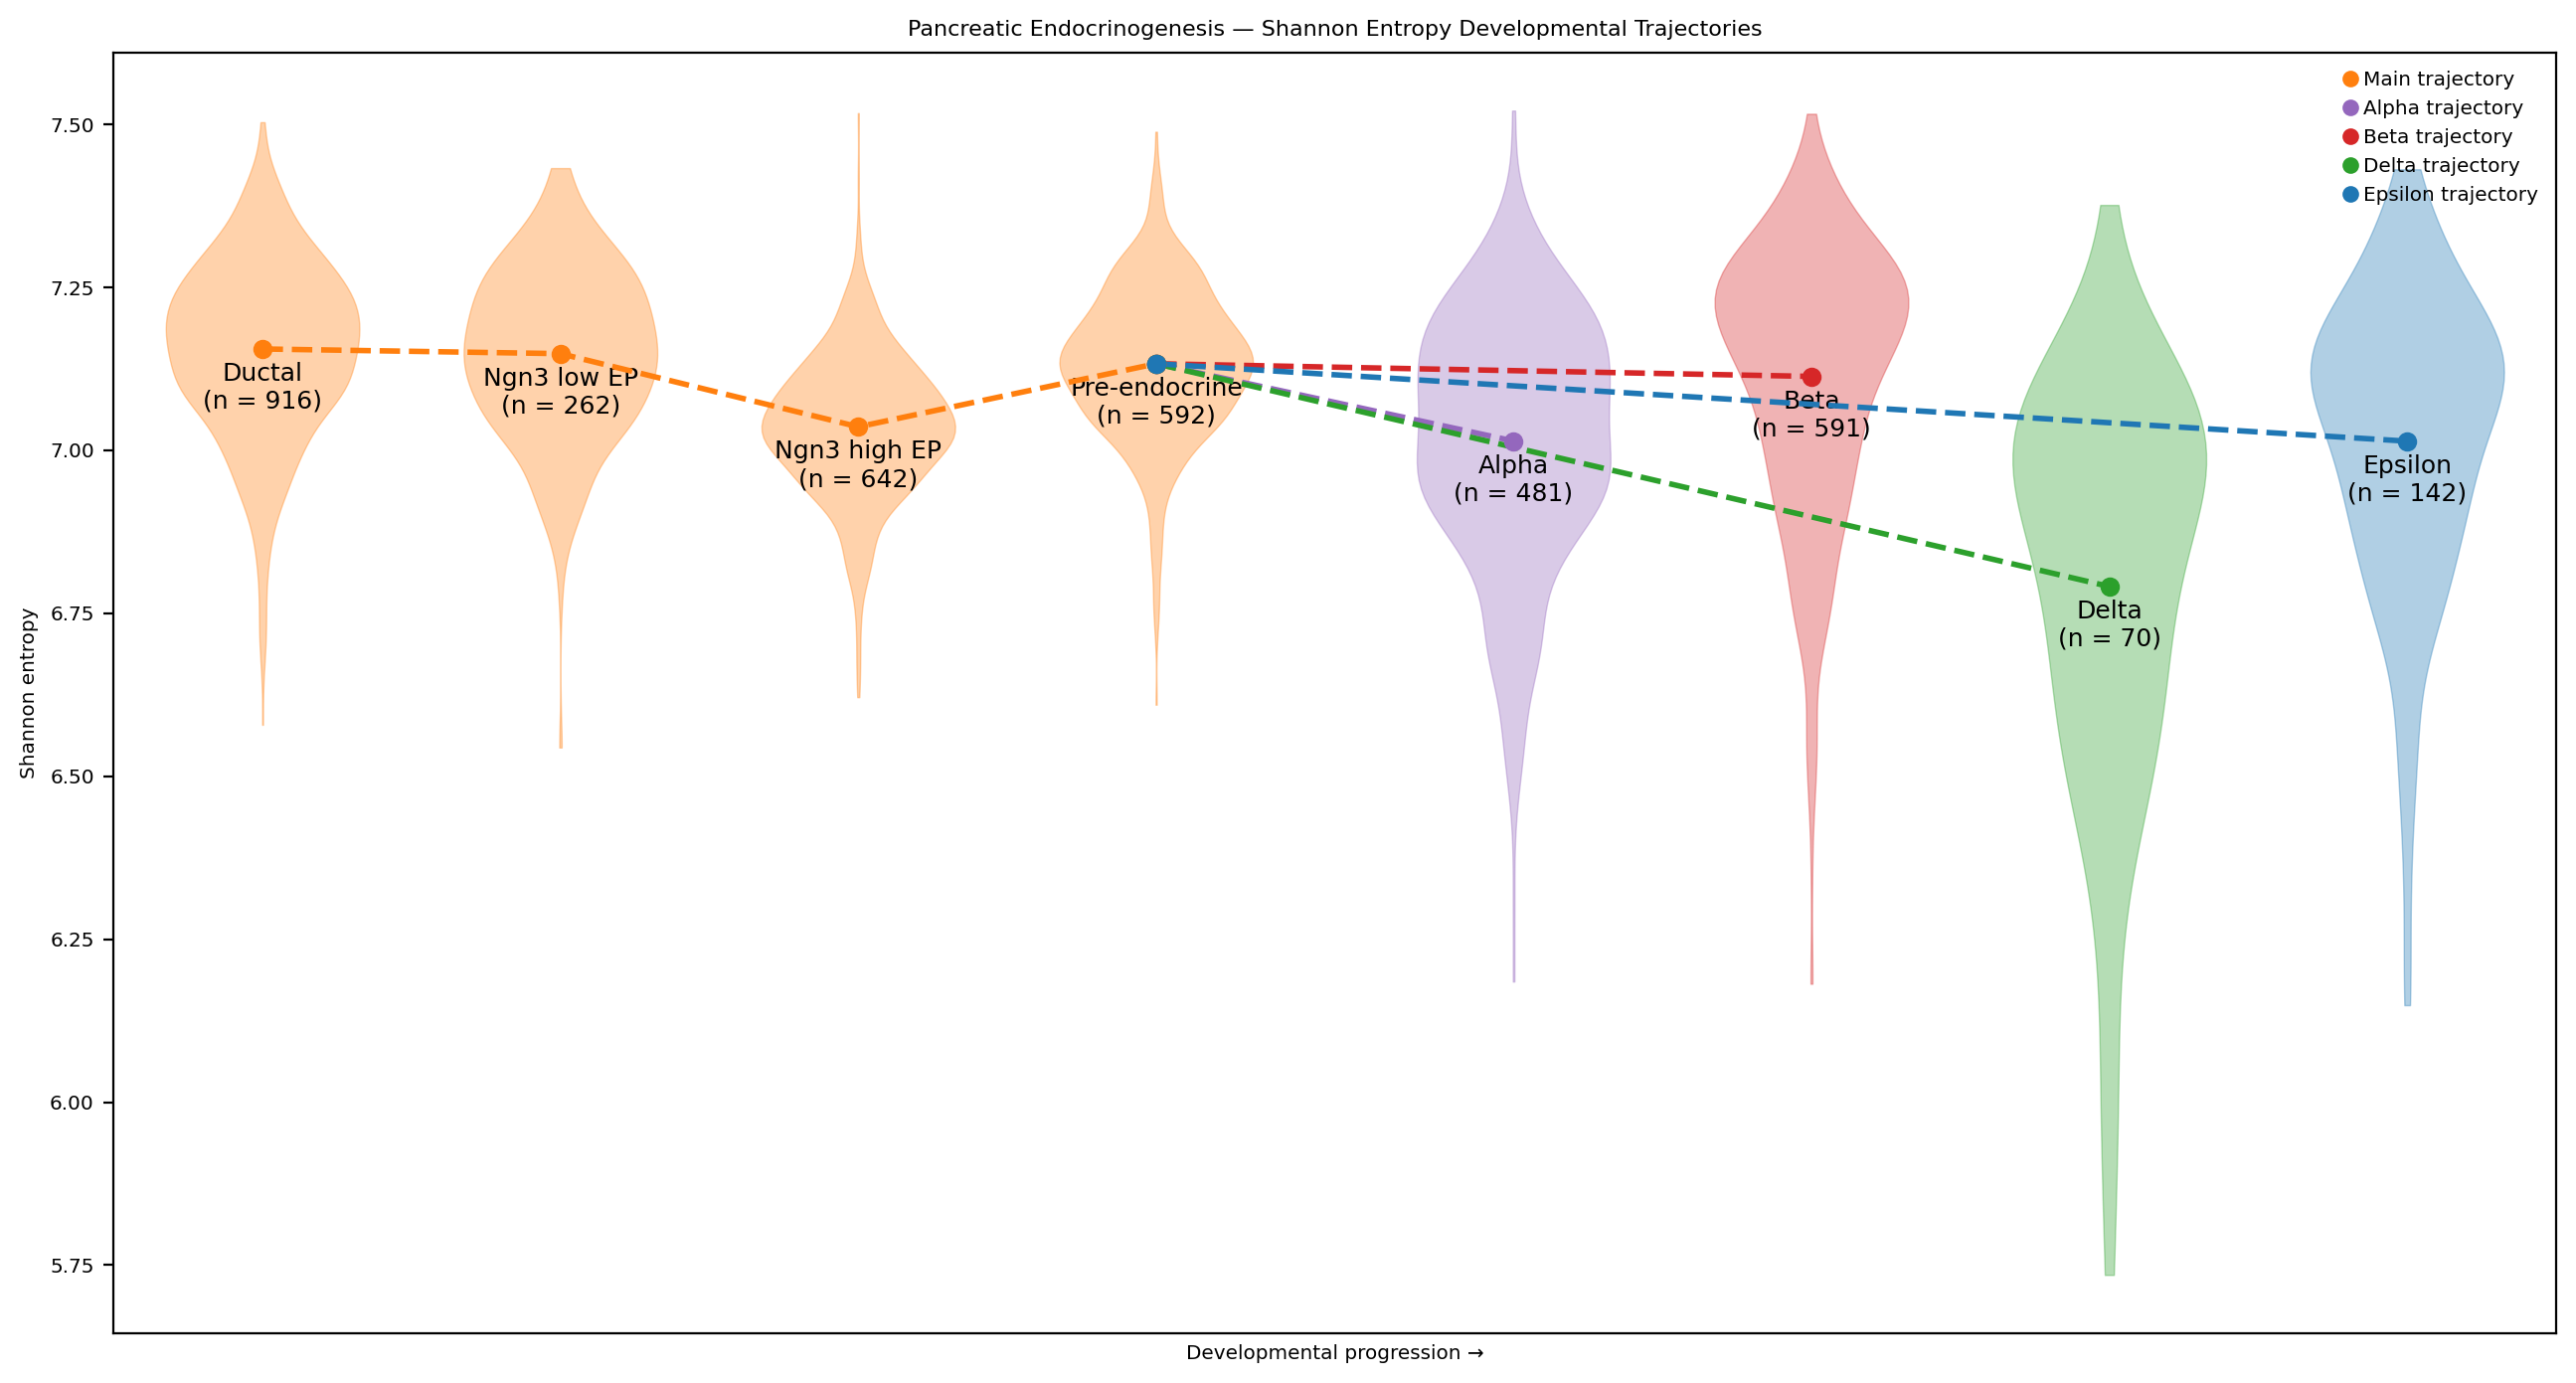

In [11]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine",
    "Alpha",
    "Beta",
    "Delta",
    "Epsilon"
]


# ============================================================
# GET SHANNON ENTROPY DISTRIBUTIONS
# ============================================================

entropy_groups = {
    name: adata.obs.loc[
        adata.obs["clusters"] == name,
        "Shannon_entropy"
    ].dropna().values
    for name in cluster
}


# ============================================================
# MEAN SHANNON ENTROPY
# ============================================================

entropy_means = {
    name: np.mean(values)
    for name, values in entropy_groups.items()
    if len(values) > 0
}


# ============================================================
# NUMBER OF CELLS
# ============================================================

cell_counts = {
    name: len(entropy_groups[name])
    for name in entropy_groups
}


# ============================================================
# X POSITIONS
#
# Developmental layout:
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
#                                                   │
#                         ┌─────────────────────────┼──────────────
#                         ↓                         ↓
#                       Alpha                     Beta
#                         ↓                         ↓
#                       Delta                     Epsilon
#
# We arrange the four terminal endocrine populations
# horizontally after Pre-endocrine.
# ============================================================

x = {

    # Main trajectory
    "Ductal":          0.0,
    "Ngn3 low EP":     1.0,
    "Ngn3 high EP":    2.0,
    "Pre-endocrine":   3.0,

    # Endocrine branches
    "Alpha":           4.2,
    "Beta":            5.2,
    "Delta":           6.2,
    "Epsilon":         7.2,
}


# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":  "tab:orange",
    "alpha": "tab:purple",
    "beta":  "tab:red",
    "delta": "tab:green",
    "epsilon": "tab:blue"
}


# ============================================================
# TRAJECTORY ASSIGNMENT
# ============================================================

trajectory = {

    # Main developmental trajectory
    "Ductal":        "main",
    "Ngn3 low EP":   "main",
    "Ngn3 high EP":  "main",
    "Pre-endocrine": "main",

    # Endocrine branches
    "Alpha":         "alpha",
    "Beta":          "beta",
    "Delta":         "delta",
    "Epsilon":       "epsilon",
}


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# DRAW VIOLINS
# ============================================================

for name in cluster:

    if name not in entropy_groups:
        continue

    values = entropy_groups[name]

    if len(values) == 0:
        continue

    color = colors[trajectory[name]]

    vp = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Color violin according to developmental trajectory
    for body in vp["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.35)


# ============================================================
# HELPER FUNCTION
# ============================================================

def plot_entropy_trajectory(ax, path, color, label):

    # --------------------------------------------------------
    # Mean points
    # --------------------------------------------------------

    for name in path:

        if name not in entropy_means:
            continue

        ax.plot(
            x[name],
            entropy_means[name],
            "o",
            color=color,
            markersize=6,
            zorder=5
        )

    # --------------------------------------------------------
    # Connecting trajectory
    # --------------------------------------------------------

    ax.plot(
        [x[name] for name in path],
        [entropy_means[name] for name in path],
        "o--",
        color=color,
        linewidth=2,
        markersize=5,
        label=label,
        zorder=4
    )


# ============================================================
# MAIN TRAJECTORY
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Ductal",
        "Ngn3 low EP",
        "Ngn3 high EP",
        "Pre-endocrine"
    ],
    colors["main"],
    "Main trajectory"
)


# ============================================================
# ALPHA BRANCH
#
# Pre-endocrine → Alpha
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Pre-endocrine",
        "Alpha"
    ],
    colors["alpha"],
    "Alpha trajectory"
)


# ============================================================
# BETA BRANCH
#
# Pre-endocrine → Beta
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Pre-endocrine",
        "Beta"
    ],
    colors["beta"],
    "Beta trajectory"
)


# ============================================================
# DELTA BRANCH
#
# Pre-endocrine → Delta
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Pre-endocrine",
        "Delta"
    ],
    colors["delta"],
    "Delta trajectory"
)


# ============================================================
# EPSILON BRANCH
#
# Pre-endocrine → Epsilon
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Pre-endocrine",
        "Epsilon"
    ],
    colors["epsilon"],
    "Epsilon trajectory"
)


# ============================================================
# LABELS
# ============================================================

for name in cluster:

    if name not in entropy_means:
        continue

    ax.text(
        x[name],
        entropy_means[name] - 0.02,
        f"{name}\n(n = {cell_counts[name]})",
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 7.7)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("Shannon entropy")

ax.set_title(
    "Pancreatic Endocrinogenesis — Shannon Entropy Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()